In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

```markdown
# Resume Project: Multi-Class Emotion Classification using NLP
**Technical Stack:** Python, Pandas, NLTK, Scikit-Learn, Seaborn, Matplotlib  

### Project Workflow:
1. **Data Engineering:** Dataset ingestion and mapping category targets.
2. **Text Preprocessing Pipeline:** Case folding, punctuation and digit stripping, stopword elimination, and custom filtering.
3. **Feature Engineering:** Comparative Vectorization (Bag-of-Words vs. TF-IDF with N-grams).
4. **Model Architecture:** Training Multi-class Logistic Regression & Multinomial Naive Bayes models.
5. **Evaluation Matrix:** Classification reports, Confusion Matrix visualization.
```

```markdown
## Step 1: Data Ingestion and Preparation
We load the emotion dataset (`train.txt`), map numerical targets to categories, and examine the class balance.
```

In [34]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Safely load local dataset from train.txt
if os.path.exists('train.txt'):
    df = pd.read_csv('train.txt', sep=';', header=None, names=['text', 'emotion'])
else:
    # Fallback to loading from Hugging Face if file doesn't exist
    from datasets import load_dataset
    dataset = load_dataset('dair-ai/emotion')
    df = pd.DataFrame(dataset['train'])
    label_map = {0: 'sadness', 1: 'joy', 2: 'love', 3: 'anger', 4: 'fear', 5: 'surprise'}
    df['emotion'] = df['label'].map(label_map)
    df = df[['text', 'emotion']]

# Map target emotions to numerical labels
emotion_to_num = {v: k for k, v in enumerate(df['emotion'].unique())}
df['label'] = df['emotion'].map(emotion_to_num)

print(f"Dataset Shape: {df.shape}")
print("\nClass Distribution:")
print(df['emotion'].value_counts())

Dataset Shape: (16000, 3)

Class Distribution:
emotion
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64


```markdown
## Step 2: Advanced Text Preprocessing Pipeline
We establish clean, modular preprocessing functions covering case folding, punctuation, digits, and NLTK-driven stopword removal.
```

In [35]:
import string
import nltk
from nltk.corpus import stopwords

# Download necessary NLTK corpora
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)

stop_words = set(stopwords.words('english'))

def preprocess_pipeline(text):
    # 1. Lowercasing
    text = text.lower()

    # 2. Remove Punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # 3. Remove Numbers/Digits
    text = ''.join([char for char in text if not char.isdigit()])

    # 4. Tokenize and Remove Stopwords
    tokens = text.split()
    cleaned_tokens = [word for word in tokens if word not in stop_words]

    return ' '.join(cleaned_tokens)

# Apply the pipeline to create the 'clean_text' column
df['clean_text'] = df['text'].apply(preprocess_pipeline)

print("Original:", df['text'].iloc[1])
print("Cleaned: ", df['clean_text'].iloc[1])

Original: i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake
Cleaned:  go feeling hopeless damned hopeful around someone cares awake


```markdown
## Step 3: Feature Engineering (TF-IDF & N-grams Vectorization)
We convert the preprocessed corpus into mathematical matrices using both Unigrams and Bigrams.
```

In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

# Define TF-IDF with unigrams and bigrams, limited to top features for performance
vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)

# Split Dataset into Train and Test
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['clean_text'], df['label'], test_size=0.2, random_state=42, stratify=df['label']
)

# Fit and Transform Features
X_train = vectorizer.fit_transform(X_train_raw)
X_test = vectorizer.transform(X_test_raw)

print(f"Train Feature Matrix Shape: {X_train.shape}")
print(f"Test Feature Matrix Shape: {X_test.shape}")

Train Feature Matrix Shape: (12800, 5000)
Test Feature Matrix Shape: (3200, 5000)


```markdown
## Step 4: Model Training and Evaluation
We evaluate a Logistic Regression baseline model and generate comprehensive performance analytics.
```

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Initialize and train the model
model = LogisticRegression(max_iter=500, class_weight='balanced')
model.fit(X_train, y_train)

# Predict on Test set
y_pred = model.predict(X_test)

# Reverse target labels for display
target_names = [k for k, v in sorted(emotion_to_num.items(), key=lambda item: item[1])]

# Print metrics
print("Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=target_names))

Classification Report:

              precision    recall  f1-score   support

     sadness       0.94      0.92      0.93       933
       anger       0.89      0.88      0.88       432
        love       0.76      0.90      0.82       261
    surprise       0.74      0.94      0.83       115
        fear       0.91      0.86      0.88       387
         joy       0.93      0.90      0.91      1072

    accuracy                           0.90      3200
   macro avg       0.86      0.90      0.88      3200
weighted avg       0.90      0.90      0.90      3200



```markdown
## Step 5: Visualizing Results (Confusion Matrix)
```

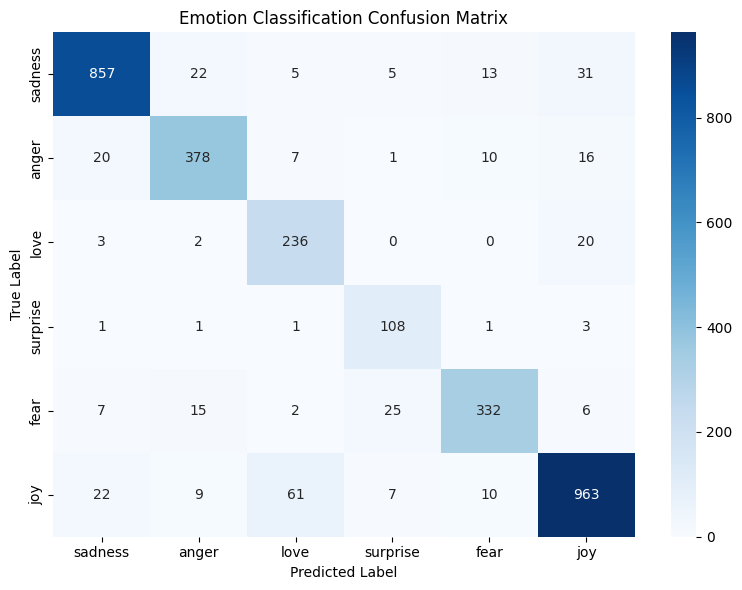

In [38]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=target_names, yticklabels=target_names, cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Emotion Classification Confusion Matrix')
plt.tight_layout()
plt.show()